# 09 — Train Neural Network Baseline Classifier

## Objective

The purpose of this notebook is to develop and train a **feedforward artificial neural network (ANN)** to classify pork rasher packaging images as either **PASS** or **FAIL**, based on the presence of packaging defects.

This model builds upon the original logistic regression baseline developed in Notebook 04, allowing the performance of a nonlinear neural network to be compared against a simpler linear classification model.

## Methodology

The neural network will use the same six image features extracted in Notebook 03:

- Mean Red (R), Green (G), and Blue (B) pixel intensities.
- Standard deviation of Red (R), Green (G), and Blue (B) pixel intensities.

These features are extracted from **entire images**, rather than subdividing images into smaller regions.

A Multilayer Perceptron (MLP) will be implemented using `MLPClassifier` from scikit-learn. The network will contain an input layer, hidden

### Setup and dependencies
Install the packages needed to load tabular data and train a classifier.

In [1]:
# Install dependencies in the active notebook environment.
%pip install pandas
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import pandas for handling tabular feature data.
import pandas as pd

# Import the neural network classifier.
from sklearn.neural_network import MLPClassifier

# Import utilities for building a preprocessing and training pipeline.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

### Load training features
Read the CSV produced by the earlier feature-extraction workflow.

In [3]:
# Load one row of precomputed colour features per training image.
features_df = pd.read_csv("../data/processed/train_features.csv")

### Select predictors and labels
The six RGB statistics form the inputs (`X_train`); `label` is the outcome the classifier learns to predict.

In [4]:
# Select six per-image colour measurements as model inputs.
# Keep labels separate so they are not accidentally included as predictors.
#Define inputs
X_train = features_df[
    [
        "mean_red",
        "mean_green",
        "mean_blue",
        "std_red",
        "std_green",
        "std_blue"
    ]
]

y_train = features_df["label"]

### Configure the neural network
Define a reproducible multilayer perceptron (MLP) architecture. Standardise the six RGB input features before training and apply L2 regularisation to reduce overfitting.

In [5]:
# Fix the model seed so supported stochastic operations are repeatable.
RANDOM_SEED = 67

In [6]:
# Define the neural network training pipeline.
model = Pipeline([

    # Step 1: Standardise all six RGB input features.
    # Each feature will have approximately zero mean and unit variance.
    # This helps the neural network train more effectively.
    ("scaler", StandardScaler()),

    # Step 2: Define the artificial neural network.
    ("classifier", MLPClassifier(

        # Two hidden layers containing 16 and 8 neurons.
        hidden_layer_sizes=(16, 8),

        # ReLU activation introduces nonlinear relationships.
        activation="relu",

        # Adam optimiser adjusts weights during training.
        solver="adam",

        # L2 regularisation to help reduce overfitting.
        alpha=0.01,

        # Maximum number of training iterations.
        max_iter=1000,

        # Use the same random seed as the baseline.
        random_state=RANDOM_SEED
    ))
])

### Train the neural network
Fit the neural network using the existing whole-image training features and PASS/FAIL labels. The model will learn relationships between RGB statistics and packaging quality.

In [7]:
from sklearn.utils.class_weight import compute_sample_weight
import sklearn

# Calculate sample weights based on the class distribution.
# The minority PASS class receives a larger weight,
# while the majority FAIL class receives a smaller weight.
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Display the weights assigned to each class.
for label in y_train.unique():

    class_weight = sample_weights[y_train == label][0]

    print(f"{label} weight: {class_weight:.3f}")

# Train the neural network using balanced sample weights.
# The pipeline standardises the RGB features before training.
model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

FAIL weight: 0.628
PASS weight: 2.448


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U4](2,)","['FAIL','PASS']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['mean_red','mean_green','mean_blue','std_red','std_green','std_blue']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


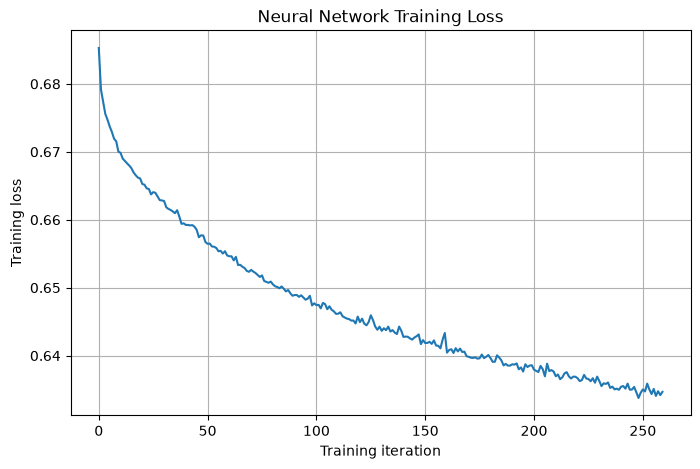

In [8]:
import matplotlib.pyplot as plt

# Access the trained neural network within the pipeline.
mlp = model.named_steps["classifier"]

# Plot the loss recorded throughout training.
plt.figure(figsize=(8, 5))

plt.plot(mlp.loss_curve_)

plt.xlabel("Training iteration")
plt.ylabel("Training loss")
plt.title("Neural Network Training Loss")

plt.grid(True)
plt.show()

### Save the trained neural network
Save the trained neural network and fitted feature scaler using Joblib. The saved pipeline will be loaded into a separate validation notebook to evaluate performance against the original logistic regression baseline.

In [9]:
# Import tools for saving Python objects and constructing file paths.
import joblib
from pathlib import Path

In [10]:
# Define the project and model output directories.
PROJECT_ROOT = Path("..")
MODEL_DIR = PROJECT_ROOT / "models"

# Create the models directory if it does not already exist.
MODEL_DIR.mkdir(exist_ok=True)

# Give the neural network its own filename.
MODEL_PATH = MODEL_DIR / "baseline_neural_network.joblib"

# Save the complete pipeline, including the scaler and MLP.
joblib.dump(model, MODEL_PATH)

print("Neural network model saved to:", MODEL_PATH)

Neural network model saved to: ..\models\baseline_neural_network.joblib


In [11]:
# Count the number of training examples belonging to each class.
print("Training class distribution:")
print(y_train.value_counts())

# Calculate the percentage belonging to each class.
print("\nClass proportions:")
print(y_train.value_counts(normalize=True) * 100)

Training class distribution:
label
FAIL    2665
PASS     684
Name: count, dtype: int64

Class proportions:
label
FAIL    79.575993
PASS    20.424007
Name: proportion, dtype: float64
